In [37]:
#INTEGRANTES:
#LUCAS MELO DOS SANTOS
#GABRIEL GREGORIO DOS SANTOS VITOR
#MATHEUS HENRIQUE DE OLIVEIRA GARCIA

In [1]:
!pip install torch torchvision torchaudio
!pip install " numpy ==1.26.4 "

  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user


In [2]:
!pip install -q --no-deps git+https://github.com/tommasocarraro/LTNtorch.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
#!/usr/bin/env python
# coding: utf-8

# In[32]:
import torch
import torch.nn as nn
import ltn
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# In[33]:
# Configure o LTNtorch para usar o dispositivo apropriado.
ltn.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {ltn.device}")

Using device: cpu


In [6]:
# In[34]:
# 1. DEFINIR CONECTIVOS LÓGICOS E QUANTIFICADORES (REQUERIDOS NO LTNTORCH)
Not = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg = ltn.fuzzy_ops.SatAgg()

In [7]:
# In[35]:
# 2. CRIAR OBJETOS LTN (Constantes e Variáveis)
red_ball = ltn.Constant(torch.tensor([1.0, 0.0, 0.0]), trainable=False)
blue_cube = ltn.Constant(torch.tensor([0.0, 0.0, 1.0]), trainable=False)

balls = ltn.Variable("balls", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.5, 0.0, 0.5],
]))
cubes = ltn.Variable("cubes", torch.tensor([
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
    [0.5, 0.5, 0.5],
]))

In [8]:
# In[36]:
# 3. DEFINIR PREDICADOS (Propriedades/relações lógicas)
class ColorPredicate(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        if hasattr(x, 'value'):
            x = x.value
        return self.network(x).squeeze()

In [9]:
is_red = ltn.Predicate(ColorPredicate())
is_blue = ltn.Predicate(ColorPredicate())
is_round = ltn.Predicate(ColorPredicate())

In [10]:
# 4. DEFINIR AXIOMAS LÓGICOS (Base de conhecimento)
def axioms():
    facts = [
        is_red(red_ball),
        is_blue(blue_cube),
        is_round(red_ball),
        Not(is_round(blue_cube))
    ]
    rules = [
        Forall(balls, is_round(balls)),
        Forall(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)),
            Implies(is_red(ltn.Variable("x", torch.randn(10, 3, device=ltn.device))),
            is_round(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)))))
    ]
    all_axioms = facts + rules
    return sat_agg(*all_axioms)

In [11]:
# 5. VERIFICAÇÃO DE SATISFATÓRIA (Raciocínio)
def check_satisfiability():
    sat_level = axioms()
    print(f"Knowledge base satisfaction level: {sat_level.item():.4f}")
    return sat_level

In [12]:
# 6. TREINAMENTO DOS PREDICADOS (Aprendendo com os dados)
def train_predicates(epochs=100):
    parameters = list(is_red.model.parameters()) + \
                 list(is_blue.model.parameters()) + \
                 list(is_round.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("\n=== TRAINING PREDICATES ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat_loss = 1 - axioms()
        sat_loss.backward()
        optimizer.step()
        if epoch % 20 == 0:
            print(f"Epoch {epoch}: Satisfaction = {1-sat_loss.item():.4f}")

In [13]:
# In[43]:
# 7. QUERYING THE KNOWLEDGE BASE (Inference)
def query_knowledge_base():
    print("\n=== QUERYING KNOWLEDGE BASE ===")
    # Query 1: Is the red ball red?
    query1 = is_red(red_ball)
    print(f"Q1: Is the red ball red? A: {query1.value.item():.4f}")

    # Query 2: Is the blue cube round?
    query2 = is_round(blue_cube)
    print(f"Q2: Is the blue cube round? A: {query2.value.item():.4f}")

    # Query 3: Are all balls round? (Universal quantification)
    all_balls_round = Forall(balls, is_round(balls))
    print(f"Q3: Are all balls round? A: {all_balls_round.value.item():.4f}")

In [14]:
# 8. EXECUTE O EXEMPLO COMPLETO
print("=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===")
initial_sat = check_satisfiability()
train_predicates(epochs=100)
final_sat = check_satisfiability()
query_knowledge_base()
print("\n=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===")
print("1. LTNObjects encapsulam tensores com significado lógico.")
print("2. Constantes representam entidades específicas")
print("3. As variáveis representam conjuntos quantificáveis")
print("4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]")
print("5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.")
print("6. Os quantificadores (Forall, Exists) agregam sobre a variávels")
print("7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.")
print("8. A função SatAgg combina múltiplos axiomas em uma única pontuação de satisfação.")


=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===
Knowledge base satisfaction level: 0.5326

=== TRAINING PREDICATES ===
Epoch 0: Satisfaction = 0.5334
Epoch 20: Satisfaction = 0.6757
Epoch 40: Satisfaction = 0.7593
Epoch 60: Satisfaction = 0.8714
Epoch 80: Satisfaction = 0.9187
Knowledge base satisfaction level: 0.9438

=== QUERYING KNOWLEDGE BASE ===
Q1: Is the red ball red? A: 0.9464
Q2: Is the blue cube round? A: 0.1040
Q3: Are all balls round? A: 0.9320

=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===
1. LTNObjects encapsulam tensores com significado lógico.
2. Constantes representam entidades específicas
3. As variáveis representam conjuntos quantificáveis
4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]
5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.
6. Os quantificadores (Forall, Exists) agregam sobre a variávels
7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.
8. A função SatAgg combina múltiplos axiomas em

In [15]:
# ==============================================================================
# EXTENSÃO: DIFERENTES FORMAS DE IGUALDADE EM LTN (Extensão Original)
# ==============================================================================
# In[45]:
print("\n" + "="*50)
print("EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN")
print("="*50)


EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN


In [16]:
Not_eq = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And_eq = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or_eq = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies_eq = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg_eq = ltn.fuzzy_ops.SatAgg()

In [17]:
red_object1 = ltn.Constant(torch.tensor([1.0, 0.0, 0.0], device=ltn.device), trainable=True)
red_object2 = ltn.Constant(torch.tensor([0.95, 0.05, 0.0], device=ltn.device), trainable=True)
blue_object = ltn.Constant(torch.tensor([0.0, 0.0, 1.0], device=ltn.device), trainable=True)

objects = ltn.Variable("objetos", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.95, 0.05, 0.0],
    [0.0, 0.0, 1.0],
    [0.0, 1.0, 0.0],
], device=ltn.device))
print("Experimento sobre igualdade: configuração concluída!")

# In[46]: 1. Igualdade diagonal LTN
print("\n" + "-"*30)
print("1. IGUALDADE DIAGONAL LTN")
print("-"*30)

Experimento sobre igualdade: configuração concluída!

------------------------------
1. IGUALDADE DIAGONAL LTN
------------------------------


In [18]:
class DiagonalEquality(nn.Module):
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return 0.5 * (cos_sim + 1.0)

In [19]:
# Teste da Igualdade diagonal euclidiana
Equal_Diag = ltn.Predicate(DiagonalEquality().to(ltn.device))

In [20]:
def axioms_withEquality_Diag():
    axioms = [
        Forall_eq(objects, Equal_Diag(objects, objects)),
        Equal_Diag(red_object1, red_object2),
        Equal_Diag(red_object2, red_object1),
        Implies_eq(And_eq(Equal_Diag(red_object1, red_object2), Equal_Diag(red_object2, red_object1)), Equal_Diag(red_object1, red_object1)),
        Not_eq(Equal_Diag(red_object1, blue_object))
    ]
    return sat_agg_eq(*axioms)

In [21]:
print("Testando a igualdade diagonal...")
sat_diag = axioms_withEquality_Diag()
print(f"Satisfação KB de igualdade diagonal: {sat_diag.item():.4f}")
print(f"P: Os dois objetos vermelhos são iguais? R: {Equal_Diag(red_object1, red_object2).value.item():.4f}")
print(f"P: Um objeto vermelho é igual a um objeto azul? R: {Equal_Diag(red_object1, blue_object).value.item():.4f}")

# In[50]: 2. Igualdade de cosseno
print("\n" + "-"*30)
print("2. IGUALDADE DE COSSENO.")
print("-"*30)

Testando a igualdade diagonal...
Satisfação KB de igualdade diagonal: 0.7764
P: Os dois objetos vermelhos são iguais? R: 0.9993
P: Um objeto vermelho é igual a um objeto azul? R: 0.5000

------------------------------
2. IGUALDADE DE COSSENO.
------------------------------


In [22]:
class CosineEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.tensor(1.0, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return torch.sigmoid(self.temperature * (cos_sim + 1.0) / 2.0)

Equal_Cos = ltn.Predicate(CosineEquality().to(ltn.device))

In [23]:
def axioms_withEquality_Cos():
    parameters = list(Equal_Cos.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento da Igualdade do Cosseno...")
    for epoch in range(200):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Equal_Cos(red_object2, red_object1), Not_eq(Equal_Cos(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Época {epoch}: Satisfatibilidade da igualdade do cosseno = {sat.item():.4f}, Temp = {Equal_Cos.model.temperature.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Not_eq(Equal_Cos(red_object1, blue_object)))

sat_cos = axioms_withEquality_Cos()
print(f"Satisfatibilidade KB da Igualdade do Cosseno Final: {sat_cos.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (cosseno)? A: {Equal_Cos(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: {Equal_Cos(red_object1, blue_object).value.item():.4f}")


Treinamento da Igualdade do Cosseno...
Época 0: Satisfatibilidade da igualdade do cosseno = 0.6112, Temp = 1.1000
Época 50: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5738
Época 100: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5680
Época 150: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5687
Satisfatibilidade KB da Igualdade do Cosseno Final: 0.5793
Q: Os dois objetos vermelhos são iguais (cosseno)? A: 0.8275
Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: 0.6866


In [24]:
# In[51]: 3. Igualdade Euclidiana
print("\n" + "-"*30)
print("3. IGUALDADE EUCLIDIANA")
print("-"*30)


------------------------------
3. IGUALDADE EUCLIDIANA
------------------------------


In [25]:
class EuclideanEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.gamma = nn.Parameter(torch.tensor(0.5, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        distance = torch.sum(torch.square(x_val - y_val), dim=-1)
        return torch.exp(-self.gamma * distance)

Equal_Eucl = ltn.Predicate(EuclideanEquality().to(ltn.device))


In [26]:
def axioms_withEquality_Eucl():
    parameters = list(Equal_Eucl.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento em Igualdade Euclidiana...")
    for epoch in range(150):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Equal_Eucl(red_object2, red_object1), Not_eq(Equal_Eucl(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 30 == 0:
            print(f"Época {epoch}: Satisfatibilidade da Igualdade Euclidiana = {sat.item():.4f}, Gamma = {Equal_Eucl.model.gamma.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Not_eq(Equal_Eucl(red_object1, blue_object)))

sat_eucl = axioms_withEquality_Eucl()
print(f"Satisfatibilidade final da igualdade euclidiana KB: {sat_eucl.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (euclidianos)? A: {Equal_Eucl(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: {Equal_Eucl(red_object1, blue_object).value.item():.4f}")


Treinamento em Igualdade Euclidiana...
Época 0: Satisfatibilidade da Igualdade Euclidiana = 0.8160, Gamma = 0.6000
Época 30: Satisfatibilidade da Igualdade Euclidiana = 0.9903, Gamma = 2.2782
Época 60: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4738
Época 90: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4658
Época 120: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4479
Satisfatibilidade final da igualdade euclidiana KB: 0.9917
Q: Os dois objetos vermelhos são iguais (euclidianos)? A: 0.9879
Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: 0.0076


In [27]:
# In[52]: 4. Igualdade de Variedades Aprendíveis
print("\n" + "-"*30)
print("4. IGUALDADE DE VARIEDADES APRENDÍVEIS")
print("-"*30)

class LearnableEquality(nn.Module):
    def __init__(self, input_dim=3):
        super(LearnableEquality, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim * 2, 64), nn.ELU(),
            nn.Linear(64, 32), nn.ELU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'valor') else x
        y_val = y.value if hasattr(y, 'valor') else y
        cat_inputs = torch.cat([x_val, y_val], dim=-1)
        return self.net(cat_inputs).squeeze()

Equal_Learned = ltn.Predicate(LearnableEquality(input_dim=3).to(ltn.device))



------------------------------
4. IGUALDADE DE VARIEDADES APRENDÍVEIS
------------------------------


In [28]:
def axioms_withEquality_Learned():
    parameters = list(Equal_Learned.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("Treinaento da Rede de Igualdade aprodível...")
    for epoch in range(300):
        optimizer.zero_grad()
        axioms = [
            Forall_eq(objects, Equal_Learned(objects, objects)),
            Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1),
            Not_eq(Equal_Learned(red_object1, blue_object)), Not_eq(Equal_Learned(blue_object, red_object1)),
            Implies_eq(And_eq(Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1)), Equal_Learned(red_object1, red_object1))
        ]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Satisfatibilidade com a igualdade aprendível= {sat.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Learned(objects, objects)), Equal_Learned(red_object1, red_object2), Not_eq(Equal_Learned(red_object1, blue_object)))

sat_learned = axioms_withEquality_Learned()
print(f"Satisfação final com a base de conhecimento sobre igualdade aprendível: {sat_learned.item():.4f}")
print(f"Q:Os dois objetos vermelhos são iguais (Aprendido)? A: {Equal_Learned(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: {Equal_Learned(red_object1, blue_object).value.item():.4f}")
print(f"Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: {Equal_Learned(red_object1, red_object1).value.item():.4f}")


Treinaento da Rede de Igualdade aprodível...
Epoch 0: Satisfatibilidade com a igualdade aprendível= 0.5376
Epoch 50: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 100: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 150: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 200: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 250: Satisfatibilidade com a igualdade aprendível= 0.7959
Satisfação final com a base de conhecimento sobre igualdade aprendível: 0.7113
Q:Os dois objetos vermelhos são iguais (Aprendido)? A: 1.0000
Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: 0.0000
Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: 1.0000


In [29]:
# ==============================================================================
# EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D (versão completa)
# ==============================================================================
# In[53]:
print("\n" + "=" * 60)
print("EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D")
print("=" * 60)

# Classes (figuras 2D representadas pelo centro (x, y)):
#   Circle(x), Square(x), Triangle(x)
# Relações espaciais: LeftOf(x,y), Above(x,y), Overlaps(x,y)
#
# AXIOMAS EM LÓGICA DE PRIMEIRA ORDEM (enunciado do tutorial):
# A1. ∀x ∀y (Circle(x) ∧ Square(y) → LeftOf(x,y))
# A2. ∀x ∀y (Triangle(x) ∧ Circle(y) → Above(x,y))
# A3. ∀x ∀y (Overlaps(x,y) → Overlaps(y,x))            (simetria)
# A4. ∀x ¬Overlaps(x,x)                                  (irreflexividade)
#
# CONTRIBUIÇÃO DO ALUNO (novos axiomas):
# B1. ∀x ∀y (Square(x) ∧ Triangle(y) → ¬Overlaps(x,y))   [desafio extra do enunciado]
# B2. ∀x ∀y (Circle(x) ∧ Square(y) → ¬Overlaps(x,y))
# B3. ∀x ∀y (LeftOf(x,y) → ¬LeftOf(y,x))                  (assimetria de LeftOf)
# B4. ∀x ∀y (Above(x,y)  → ¬Above(y,x))                   (assimetria de Above)
# B5. ∀x ∀y (Square(x) ∧ Circle(y) → ¬LeftOf(x,y))        (consequência de A1 + B3)
# B6. ∀x ∀y (Circle(x) ∧ Triangle(y) → ¬Above(x,y))       (consequência de A2 + B4)
#
# FATOS DE ATERRAMENTO (ligam os predicados de classe aos dados; sem eles a rede
# poderia "satisfazer" A1/A2 trivialmente fazendo Circle(x) = 0 para todo x):
# G1. ∀c Circle(c) ∧ ¬Square(c) ∧ ¬Triangle(c)   (c em Círculos)
# G2. ∀s Square(s) ∧ ¬Circle(s) ∧ ¬Triangle(s)   (s em Quadrados)
# G3. ∀t Triangle(t) ∧ ¬Circle(t) ∧ ¬Square(t)   (t em Triângulos)
# ==============================================================================
_ = torch.manual_seed(42)   # reprodutibilidade


EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D


In [30]:
# In[54]: 1. GERAÇÃO DE DADOS (Plano 2D aleatório, com semente)
# Regiões (x, y) de cada classe. Foram ajustadas em relação ao código-base porque
# lá os círculos tinham y em [0,10] e os triângulos y em [6,10]: assim, "todo
# triângulo está acima de todo círculo" (A2) era FALSO nos próprios dados.
#   círculos   : x in [0,4],  y in [0,4]   (canto inferior esquerdo)
#   quadrados  : x in [6,10], y in [0,4]   (canto inferior direito)
#   triângulos : x in [0,10], y in [6,10]  (faixa superior)
def generate_random_shapes(num_per_shape=10, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    def sample(low, high):
        low, high = torch.tensor(low), torch.tensor(high)
        return (torch.rand(num_per_shape, 2, generator=g) * (high - low) + low).to(ltn.device)
    circles   = sample([0.0, 0.0], [4.0, 4.0])
    squares   = sample([6.0, 0.0], [10.0, 4.0])
    triangles = sample([0.0, 6.0], [10.0, 10.0])
    return circles, squares, triangles

In [31]:
# In[55]: 2. PREDICADOS NEURAIS
# Obs.: o LTN já faz o produto cruzado das variáveis antes de chamar o modelo, então
# x e y chegam como tensores (N, 2) pareados. O código-base fazia unsqueeze(1)/(0)
# de novo, o que gerava RuntimeError (shape '[10, 10]' inválido para tamanho 10000).
class ShapeClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x):
        return self.net(x).squeeze(-1)

class LearnableSpatialRelation(nn.Module):
    """Relação binária aprendível a partir de UMA feature geométrica de (x, y)."""
    def __init__(self, feature_extractor):
        super().__init__()
        self.feature_extractor = feature_extractor
        self.net = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x, y):
        return self.net(self.feature_extractor(x, y)).squeeze(-1)

def left_of_features(x, y):  return (y[..., 0] - x[..., 0]).unsqueeze(-1)   # Δx
def above_features(x, y):    return (x[..., 1] - y[..., 1]).unsqueeze(-1)   # Δy
def distance_features(x, y): return torch.norm(x - y, dim=-1, keepdim=True)  # distância

is_circle   = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_square   = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_triangle = ltn.Predicate(ShapeClassifier().to(ltn.device))
left_of  = ltn.Predicate(LearnableSpatialRelation(left_of_features).to(ltn.device))
above    = ltn.Predicate(LearnableSpatialRelation(above_features).to(ltn.device))
overlaps = ltn.Predicate(LearnableSpatialRelation(distance_features).to(ltn.device))

In [32]:
# In[56]: 3. AXIOMAS LÓGICOS (FOL -> LTN)
def geo_axiom_dict(circles, squares, triangles):
    c = ltn.Variable("c", circles)
    s = ltn.Variable("s", squares)
    t = ltn.Variable("t", triangles)
    all_figs = torch.cat([circles, squares, triangles])
    x = ltn.Variable("x", all_figs)     # x e y variam sobre TODAS as figuras
    y = ltn.Variable("y", all_figs)
    return {
        # --- axiomas do enunciado ---
        "A1 Circle(c)∧Square(s) → LeftOf(c,s)":      Forall([c, s], Implies(And(is_circle(c), is_square(s)), left_of(c, s))),
        "A2 Triangle(t)∧Circle(c) → Above(t,c)":     Forall([t, c], Implies(And(is_triangle(t), is_circle(c)), above(t, c))),
        "A3 Overlaps(x,y) → Overlaps(y,x)":          Forall([x, y], Implies(overlaps(x, y), overlaps(y, x))),
        "A4 ¬Overlaps(x,x)":                         Forall(x, Not(overlaps(x, x))),
        # --- novos axiomas (contribuição) ---
        "B1 Square∧Triangle → ¬Overlaps (desafio)":  Forall([s, t], Implies(And(is_square(s), is_triangle(t)), Not(overlaps(s, t)))),
        "B2 Circle∧Square → ¬Overlaps":              Forall([c, s], Implies(And(is_circle(c), is_square(s)), Not(overlaps(c, s)))),
        "B3 LeftOf(x,y) → ¬LeftOf(y,x)":             Forall([x, y], Implies(left_of(x, y), Not(left_of(y, x)))),
        "B4 Above(x,y) → ¬Above(y,x)":               Forall([x, y], Implies(above(x, y), Not(above(y, x)))),
        "B5 Square∧Circle → ¬LeftOf":                Forall([s, c], Not(left_of(s, c))),
        "B6 Circle∧Triangle → ¬Above":               Forall([c, t], Not(above(c, t))),
        # --- aterramento das classes ---
        "G1 círculos são Circle":                    Forall(c, And(is_circle(c), And(Not(is_square(c)), Not(is_triangle(c))))),
        "G2 quadrados são Square":                   Forall(s, And(is_square(s), And(Not(is_circle(s)), Not(is_triangle(s))))),
        "G3 triângulos são Triangle":                Forall(t, And(is_triangle(t), And(Not(is_circle(t)), Not(is_square(t))))),
    }

def define_geo_axioms(circles, squares, triangles):
    return sat_agg(*geo_axiom_dict(circles, squares, triangles).values())

def print_axiom_report(circles, squares, triangles, title):
    print(f"\n--- {title} ---")
    for name, f in geo_axiom_dict(circles, squares, triangles).items():
        print(f"  {f.value.item():.4f}  {name}")

In [33]:
# In[57]: 4. TREINAMENTO (conjunto pequeno, gerado UMA única vez)
def train_geometrical_model(epochs=500, num_per_shape=10, seed=0, lr=0.01):
    parameters = []
    for pred in [is_circle, is_square, is_triangle, left_of, above, overlaps]:
        parameters += list(pred.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=lr)
    circles, squares, triangles = generate_random_shapes(num_per_shape, seed=seed)   # <- uma vez
    print("\n=== TREINANDO AXIOMAS GEOMÉTRICOS ===")
    print(f"Treino: {num_per_shape} círculos, {num_per_shape} quadrados, {num_per_shape} triângulos")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat = define_geo_axioms(circles, squares, triangles)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}: Satisfação = {sat.item():.4f}")
    return circles, squares, triangles

In [34]:
# In[58]: 5. TESTE DE GENERALIZAÇÃO EM NOVOS DADOS ALEATÓRIOS
def test_geometrical_model(num_per_shape=20, seed=123):
    print("\n=== TESTANDO EM NOVOS DADOS ALEATÓRIOS (semente diferente, nunca vistos) ===")
    tc, ts, tt = generate_random_shapes(num_per_shape, seed=seed)
    print(f"Teste: {num_per_shape} círculos, {num_per_shape} quadrados, {num_per_shape} triângulos")
    print_axiom_report(tc, ts, tt, "Satisfação de cada axioma nos dados de TESTE")

    c, s, t = ltn.Variable("c_test", tc), ltn.Variable("s_test", ts), ltn.Variable("t_test", tt)
    acc = lambda pred, truth: ((pred > 0.5) == truth).float().mean().item()

    # (a) Classificação das figuras
    print("\n[a] Acurácia da classificação (limiar 0.5):")
    print(f"    Circle   em círculos  : {(is_circle(c).value > 0.5).float().mean().item():.2%}")
    print(f"    Square   em quadrados : {(is_square(s).value > 0.5).float().mean().item():.2%}")
    print(f"    Triangle em triângulos: {(is_triangle(t).value > 0.5).float().mean().item():.2%}")

    # (b) Relações espaciais vs. verdade geométrica (pares círculo/quadrado/triângulo)
    print("\n[b] Relações espaciais vs. verdade geométrica nos pares de teste:")
    truth_left  = tc[:, 0:1] < ts[:, 0].unsqueeze(0)      # círculo.x < quadrado.x
    truth_above = tt[:, 1:2] > tc[:, 1].unsqueeze(0)      # triângulo.y > círculo.y
    print(f"    LeftOf(círculo, quadrado) = verdadeiro : acurácia {acc(left_of(c, s).value, truth_left):.2%}")
    print(f"    LeftOf(quadrado, círculo) = falso      : acurácia {acc(left_of(s, c).value, ~truth_left.T):.2%}")
    print(f"    Above(triângulo, círculo) = verdadeiro : acurácia {acc(above(t, c).value, truth_above):.2%}")
    print(f"    Above(círculo, triângulo) = falso      : acurácia {acc(above(c, t).value, ~truth_above.T):.2%}")
    print(f"    Overlaps(quadrado, triângulo) < 0.5    : {(overlaps(s, t).value < 0.5).float().mean().item():.2%}")

    # (c) Consultas (queries) lógicas quantificadas
    print("\n[c] Consultas quantificadas (valores de verdade em [0,1]):")
    q1 = Forall([c, s], Implies(And(is_circle(c), is_square(s)), left_of(c, s)))
    print(f"    Q1: ∀c∀s (Circle∧Square → LeftOf(c,s))            = {q1.value.item():.4f}")
    q2 = Forall([t, c], Implies(And(is_triangle(t), is_circle(c)), above(t, c)))
    print(f"    Q2: ∀t∀c (Triangle∧Circle → Above(t,c))           = {q2.value.item():.4f}")
    q3 = Forall([s, t], Implies(And(is_square(s), is_triangle(t)), Not(overlaps(s, t))))
    print(f"    Q3: ∀s∀t (Square∧Triangle → ¬Overlaps(s,t))       = {q3.value.item():.4f}")
    q4 = Forall(c, Exists(s, And(is_square(s), left_of(c, s))))
    print(f"    Q4: ∀c ∃s (Square(s) ∧ LeftOf(c,s))               = {q4.value.item():.4f}")
    q5 = Forall([s, c], left_of(s, c))   # deve ser FALSA: quadrados não estão à esquerda de círculos
    print(f"    Q5: ∀s∀c LeftOf(s,c)  (esperado ≈ 0)              = {q5.value.item():.4f}")

    # (d) Consultas pontuais com constantes
    c1, s1, t1 = ltn.Constant(tc[0]), ltn.Constant(ts[0]), ltn.Constant(tt[0])
    print(f"\n[d] Consultas pontuais (c1={tc[0].tolist()}, s1={ts[0].tolist()}, t1={tt[0].tolist()}):")
    for desc, val in [
        ("LeftOf(c1, s1)   [esperado alto ]", left_of(c1, s1)),
        ("LeftOf(s1, c1)   [esperado baixo]", left_of(s1, c1)),
        ("Above(t1, c1)    [esperado alto ]", above(t1, c1)),
        ("Above(c1, t1)    [esperado baixo]", above(c1, t1)),
        ("Overlaps(c1, s1) [esperado baixo]", overlaps(c1, s1)),
        ("Overlaps(s1, t1) [esperado baixo]", overlaps(s1, t1)),
        ("Circle(c1)       [esperado alto ]", is_circle(c1)),
        ("Square(c1)       [esperado baixo]", is_square(c1)),
    ]:
        print(f"    {desc}: {val.value.item():.4f}")

    # (e) Teste de estresse: pares ARBITRÁRIOS em [0,10]^2 (fora da distribuição do treino)
    g = torch.Generator().manual_seed(7)
    A = (torch.rand(300, 2, generator=g) * 10).to(ltn.device)
    B = (torch.rand(300, 2, generator=g) * 10).to(ltn.device)
    pa, pb = ltn.Variable("pa", A), ltn.Variable("pb", B)
    dx = B[:, 0].unsqueeze(0) - A[:, 0:1]          # >0  <=>  A está à esquerda de B
    dy = A[:, 1:2] - B[:, 1].unsqueeze(0)          # >0  <=>  A está acima de B
    L, Ab = left_of(pa, pb).value, above(pa, pb).value
    far = lambda d: d.abs() >= 2.0                 # faixa de |Δ| que o treino realmente cobriu
    print("\n[e] Estresse com 300x300 pares aleatórios quaisquer (não só círculo/quadrado):")
    print(f"    LeftOf: acurácia geral {acc(L, dx > 0):.2%} | com |Δx| ≥ 2: {((L > 0.5) == (dx > 0))[far(dx)].float().mean().item():.2%}")
    print(f"    Above : acurácia geral {acc(Ab, dy > 0):.2%} | com |Δy| ≥ 2: {((Ab > 0.5) == (dy > 0))[far(dy)].float().mean().item():.2%}")
    return tc, ts, tt

In [35]:
# In[59]: 6. EXECUTAR: antes do treino -> treino -> depois do treino -> teste
circles_tr, squares_tr, triangles_tr = generate_random_shapes(10, seed=0)
print_axiom_report(circles_tr, squares_tr, triangles_tr, "ANTES do treino (dados de treino)")

circles_tr, squares_tr, triangles_tr = train_geometrical_model(epochs=500)
print_axiom_report(circles_tr, squares_tr, triangles_tr, "DEPOIS do treino (dados de treino)")

tc, ts, tt = test_geometrical_model(num_per_shape=20, seed=123)


--- ANTES do treino (dados de treino) ---
  0.9388  A1 Circle(c)∧Square(s) → LeftOf(c,s)
  0.6389  A2 Triangle(t)∧Circle(c) → Above(t,c)
  0.7561  A3 Overlaps(x,y) → Overlaps(y,x)
  0.6604  A4 ¬Overlaps(x,x)
  0.9052  B1 Square∧Triangle → ¬Overlaps (desafio)
  0.9342  B2 Circle∧Square → ¬Overlaps
  0.8315  B3 LeftOf(x,y) → ¬LeftOf(y,x)
  0.8670  B4 Above(x,y) → ¬Above(y,x)
  0.8234  B5 Square∧Circle → ¬LeftOf
  0.6217  B6 Circle∧Triangle → ¬Above
  0.1171  G1 círculos são Circle
  0.0039  G2 quadrados são Square
  0.1468  G3 triângulos são Triangle

=== TREINANDO AXIOMAS GEOMÉTRICOS ===
Treino: 10 círculos, 10 quadrados, 10 triângulos
Epoch 0: Satisfação = 0.5162
Epoch 100: Satisfação = 0.9808
Epoch 200: Satisfação = 0.9969
Epoch 300: Satisfação = 0.9986
Epoch 400: Satisfação = 0.9991
Epoch 499: Satisfação = 0.9994

--- DEPOIS do treino (dados de treino) ---
  0.9997  A1 Circle(c)∧Square(s) → LeftOf(c,s)
  0.9997  A2 Triangle(t)∧Circle(c) → Above(t,c)
  0.9998  A3 Overlaps(x,y) → Over

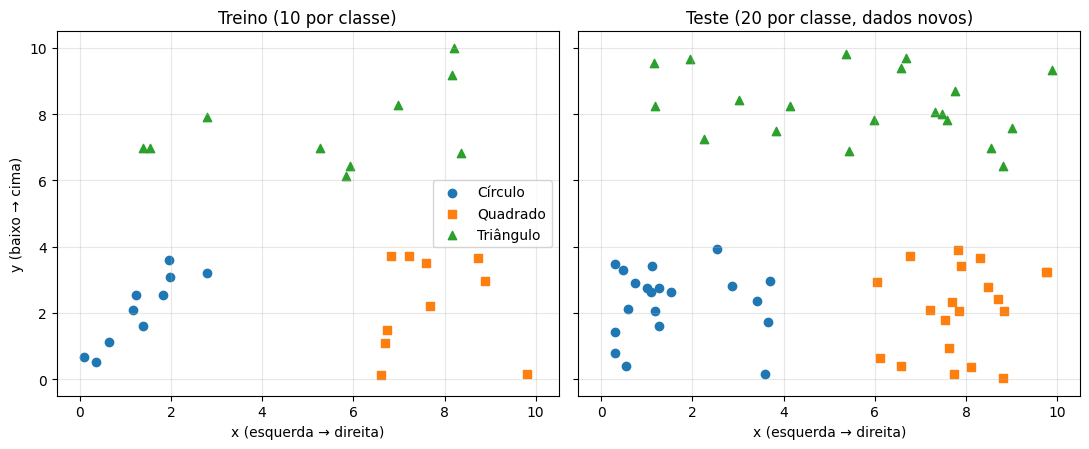

In [36]:
# In[60]: 7. VISUALIZAÇÃO: dados de treino vs. teste
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (cs, ss, ts_), title in [(axs[0], (circles_tr, squares_tr, triangles_tr), "Treino (10 por classe)"),
                                  (axs[1], (tc, ts, tt), "Teste (20 por classe, dados novos)")]:
    ax.scatter(*cs.cpu().T, marker="o", c="tab:blue",   label="Círculo")
    ax.scatter(*ss.cpu().T, marker="s", c="tab:orange", label="Quadrado")
    ax.scatter(*ts_.cpu().T, marker="^", c="tab:green", label="Triângulo")
    ax.set_title(title); ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 10.5)
    ax.set_xlabel("x (esquerda → direita)"); ax.grid(alpha=0.3)
axs[0].set_ylabel("y (baixo → cima)"); axs[0].legend(loc="center right")
plt.tight_layout(); plt.show()